# TASK A1: DATA LOADING, EDA & PREPROCESSING

## A1.1 – Load CIFAR-10 Dataset

### Objective
The objective of this task is to load the CIFAR-10 dataset using TensorFlow/Keras and understand its basic structure.

CIFAR-10 is an image classification dataset containing 60,000 colour images divided into 10 different classes.

The dataset contains:
- 50,000 training images.
- 10,000 testing images.
- Image dimensions of 32 × 32 pixels.
- Three colour channels (RGB).
- 10 different object categories.

We will load the dataset and check its shape, unique labels and data types.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import cifar10

# Load CIFAR-10 dataset
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

# Display dataset information
print("Training Images:", X_train.shape)
print("Training Labels:", y_train.shape)

print("Testing Images:", X_test.shape)
print("Testing Labels:", y_test.shape)

print("Unique Classes:", np.unique(y_train))
print("Data Type:", X_train.dtype)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1806s 11us/step
Training Images: (50000, 32, 32, 3)
Training Labels: (50000, 1)
Testing Images: (10000, 32, 32, 3)
Testing Labels: (10000, 1)
Unique Classes: [0 1 2 3 4 5 6 7 8 9]
Data Type: uint8


### Explanation

The CIFAR-10 dataset was successfully loaded using TensorFlow/Keras.

The training dataset contains 50,000 images, while the testing dataset contains 10,000 images.

Each image has a resolution of 32 × 32 pixels with three RGB colour channels.

The labels represent 10 different object categories, numbered from 0 to 9.

The images are stored in uint8 format, where pixel values range from 0 to 255.

## A1.2 – Visualise Sample Images

### Objective

In this subtask, we will visualise 50 sample images from the CIFAR-10 dataset using a 5 × 10 grid.

Each row will represent one class, and each column will display a different image.

We will also display the class name above every image to understand the visual differences between categories.

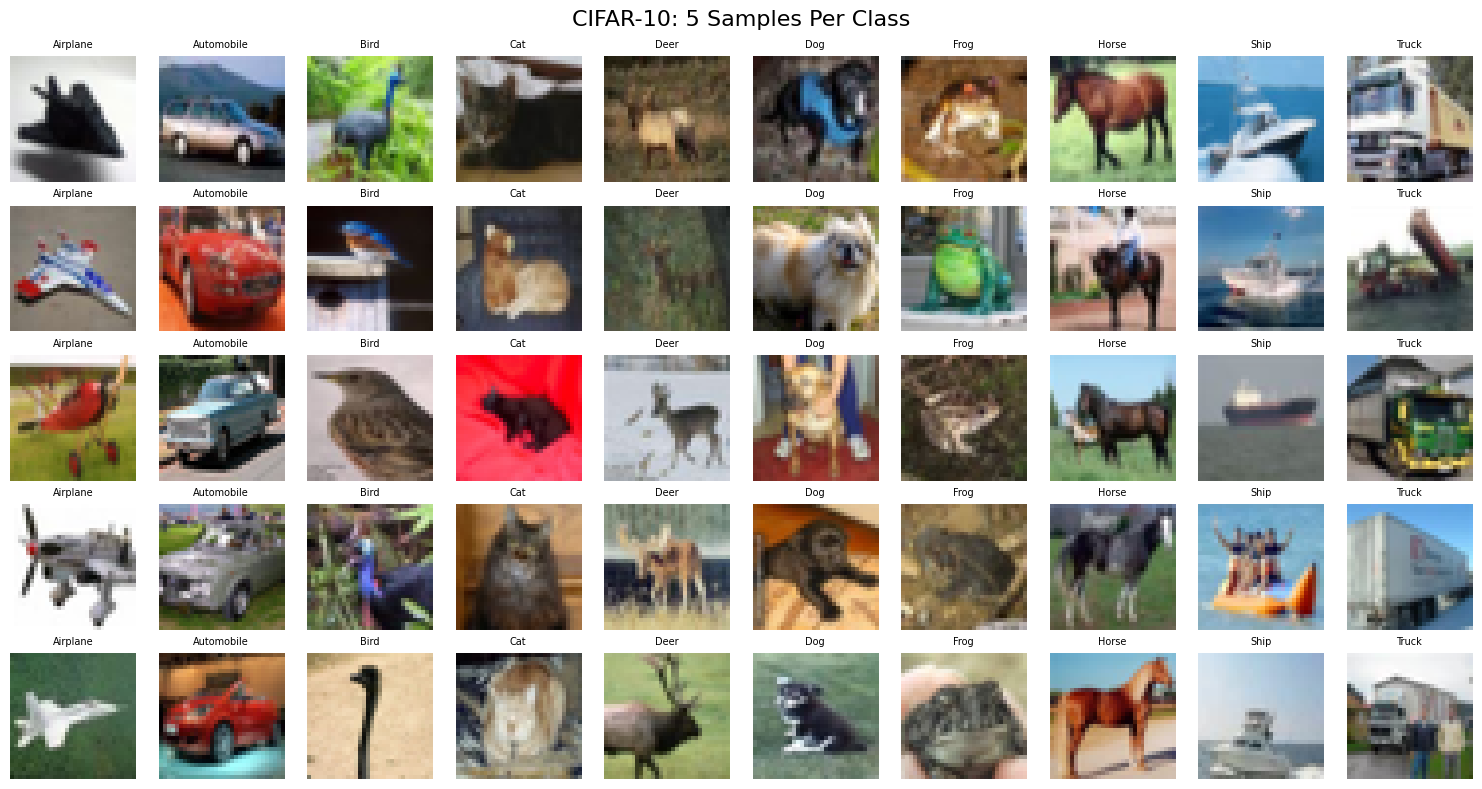

In [2]:
# CIFAR-10 class names
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

plt.figure(figsize=(15, 8))

for class_id in range(10):
    # Select 5 images from each class
    images = X_train[y_train.flatten() == class_id][:5]

    for j in range(5):
        plt.subplot(5, 10, j * 10 + class_id + 1)
        plt.imshow(images[j])
        plt.title(class_names[class_id], fontsize=7)
        plt.axis('off')

plt.suptitle("CIFAR-10: 5 Samples Per Class", fontsize=16)
plt.tight_layout()
plt.show()

### Explanation

The visualisation displays 50 images from the CIFAR-10 dataset.

Each row contains five images belonging to the same class.

We can observe that some categories have similar visual appearances.

For example:
- Cats and dogs may have similar shapes.
- Automobiles and trucks may look similar.
- Ships and airplanes have different backgrounds but can contain visual similarities.

These similarities make image classification challenging and demonstrate why CNN models are useful.

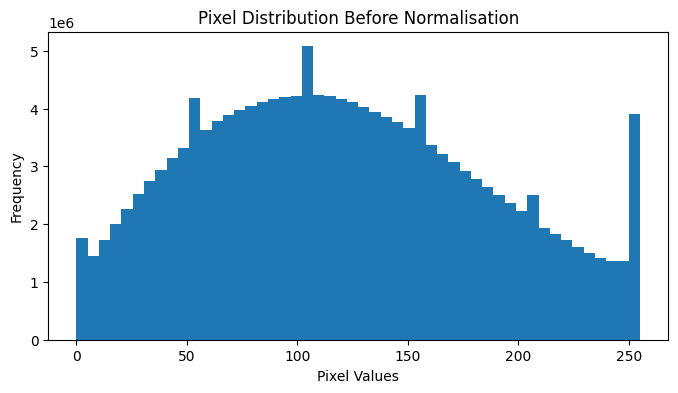

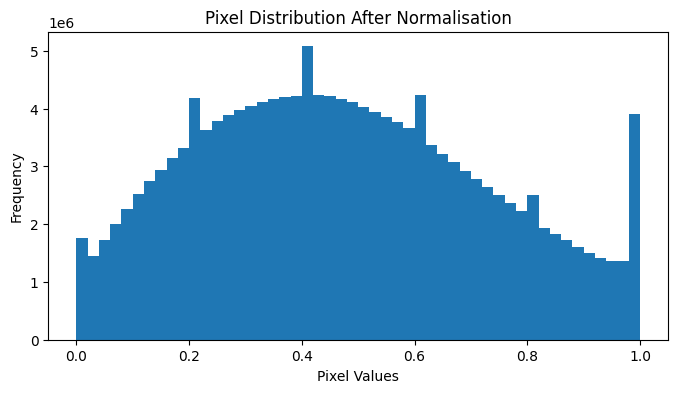

Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [3]:
# Display pixel distribution before normalisation
plt.figure(figsize=(8, 4))

plt.hist(X_train.flatten(), bins=50)
plt.title("Pixel Distribution Before Normalisation")
plt.xlabel("Pixel Values")
plt.ylabel("Frequency")
plt.show()

# Normalise images
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Display pixel distribution after normalisation
plt.figure(figsize=(8, 4))

plt.hist(X_train.flatten(), bins=50)
plt.title("Pixel Distribution After Normalisation")
plt.xlabel("Pixel Values")
plt.ylabel("Frequency")
plt.show()

print("Minimum Pixel Value:", X_train.min())
print("Maximum Pixel Value:", X_train.max())

### Explanation

Before normalisation, pixel values ranged between 0 and 255.

After dividing the pixel values by 255, all values were converted into a range between 0 and 1.

The histograms help us understand the distribution of pixel intensities before and after normalisation.

Normalisation improves numerical stability and helps gradient-based optimisation algorithms train neural networks more effectively.

It also prevents large input values from creating unnecessarily large updates during training.

## A1.4 – One-Hot Encode Labels

### Objective

In this subtask, we will convert the original numerical class labels into one-hot encoded format.

CIFAR-10 contains 10 classes numbered from 0 to 9.

One-hot encoding converts each class label into a vector containing 10 positions.

For example, class 3 becomes:

[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]

This format is useful when training a CNN model with categorical cross-entropy loss.

In [4]:
from tensorflow.keras.utils import to_categorical

# Convert labels into one-hot encoding
y_train_one = to_categorical(y_train, 10)
y_test_one = to_categorical(y_test, 10)

# Display results
print("Original Label:", y_train[0])
print("Encoded Label:", y_train_one[0])

print("Training Labels Shape:", y_train_one.shape)
print("Testing Labels Shape:", y_test_one.shape)

Original Label: [6]
Encoded Label: [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
Training Labels Shape: (50000, 10)
Testing Labels Shape: (10000, 10)


### Explanation

The original labels were successfully converted into one-hot encoded vectors.

Each label now contains 10 positions, representing the 10 CIFAR-10 classes.

Only one position contains the value 1, while all other positions contain 0.

The training labels now have a shape of (50000, 10), and the testing labels have a shape of (10000, 10).

This representation is suitable for multiclass classification using categorical cross-entropy loss.

## A1.5 – CNN vs ANN for Image Classification

### 1. Artificial Neural Network (ANN)

An Artificial Neural Network processes an image by flattening it into a one-dimensional vector.

For example, a CIFAR-10 image of size 32 × 32 × 3 becomes a vector containing 3,072 values.

However, flattening removes the original spatial arrangement of pixels.

As a result, an ANN may struggle to identify important image features such as edges, shapes and object patterns.

### 2. Convolutional Neural Network (CNN)

A Convolutional Neural Network is specifically designed for image processing.

It uses convolutional filters to extract important features from images.

CNNs can automatically identify:
- Edges and corners.
- Shapes and textures.
- Object patterns.
- Complex visual features.

CNNs also preserve spatial relationships between neighbouring pixels.

### 3. Parameter Sharing

CNNs use the same filter weights across different image locations.

For example, a 3 × 3 filter with three input channels contains only 27 weights, excluding the bias.

The same filter is applied across the image.

This significantly reduces the number of parameters compared with a fully connected ANN.

### 4. Why CNN is Better for Image Classification

CNNs are generally more effective than basic ANNs for image classification because they preserve spatial information, automatically extract features and use parameter sharing.

Therefore, we will use a CNN architecture to classify the CIFAR-10 images.

### Conclusion

CNNs are more suitable for image classification tasks because they learn spatial features directly from images while maintaining fewer parameters through shared convolutional filters.

# TASK A2: CONVOLUTION OPERATION, PADDING & STRIDES

## A2.1 – Manual Convolution Demonstration

### Objective

The objective of this task is to understand how convolution operations work in CNNs.

We will:
1. Select one image from the CIFAR-10 dataset.
2. Convert the RGB image into grayscale.
3. Create a 3 × 3 edge detection kernel.
4. Apply convolution using scipy.signal.convolve2d.
5. Display the original grayscale image and its convolved output.

The convolution operation applies a small filter over an image to extract important features such as edges and boundaries.

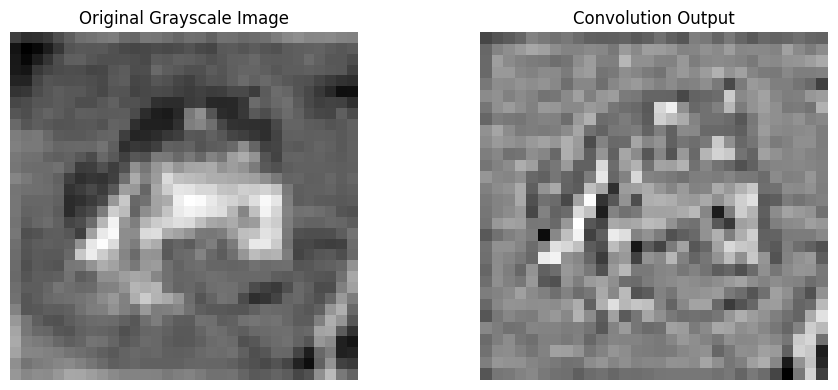

Original Shape: (32, 32)
Output Shape: (30, 30)


In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d

# Select one CIFAR-10 image
image = X_train[0]

# Convert RGB image to grayscale
gray = np.mean(image, axis=2)

# Create 3x3 edge detection kernel
kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])

# Apply convolution
output = convolve2d(gray, kernel, mode='valid')

# Display images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(output, cmap='gray')
plt.title("Convolution Output")
plt.axis('off')

plt.tight_layout()
plt.show()

print("Original Shape:", gray.shape)
print("Output Shape:", output.shape)

### Explanation

First, we selected one image from the CIFAR-10 training dataset.

The RGB image was converted into grayscale by calculating the average of its three colour channels.

Next, we created a 3 × 3 edge detection kernel and applied convolution using scipy.signal.convolve2d.

The filter moves across the image and calculates values based on the surrounding pixels.

The resulting image highlights edges and boundaries.

The original image has dimensions of 32 × 32, while the convolution output has dimensions of 30 × 30 because VALID convolution does not add padding.

This demonstrates how CNN convolution layers extract useful visual features from images.

## A2.2 – Padding: VALID vs SAME

### Objective

In this subtask, we will understand the difference between VALID and SAME padding in CNNs.

1. VALID Padding:
   - No extra pixels are added around the image.
   - The output dimensions become smaller.

2. SAME Padding:
   - Zero-padding is added around the image when required.
   - The output dimensions are preserved for stride 1.

We will create two simple CNN models and compare their output shapes using a 3 × 3 convolution filter.

In [6]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D

# Create input layer
inputs = Input(shape=(32, 32, 3))

# VALID padding model
valid_output = Conv2D(
    8, (3, 3), padding='valid'
)(inputs)

valid_model = Model(inputs, valid_output)

# SAME padding model
same_output = Conv2D(
    8, (3, 3), padding='same'
)(inputs)

same_model = Model(inputs, same_output)

# Display output shapes
print("VALID Output Shape:", valid_model.output_shape)
print("SAME Output Shape:", same_model.output_shape)

VALID Output Shape: (None, 30, 30, 8)
SAME Output Shape: (None, 32, 32, 8)


## A2.3 – Strides Effect

### Objective

In this subtask, we will understand how strides affect the output dimensions of convolution layers.

A stride determines how many pixels the convolution filter moves at each step.

We will compare two configurations:

1. Stride = 1:
   - The filter moves one pixel at a time.
   - More spatial information is preserved.

2. Stride = 2:
   - The filter moves two pixels at a time.
   - The output dimensions become smaller.

We will use a 3 × 3 convolution filter and compare the output shapes.

In [7]:
# Input layer
inputs = Input(shape=(32, 32, 3))

# Stride 1 with VALID padding
output_1 = Conv2D(
    8, (3, 3), strides=1, padding='valid'
)(inputs)

model_1 = Model(inputs, output_1)

# Stride 2 with SAME padding
output_2 = Conv2D(
    8, (3, 3), strides=2, padding='same'
)(inputs)

model_2 = Model(inputs, output_2)

# Print output shapes
print("Stride 1 Output:", model_1.output_shape)
print("Stride 2 Output:", model_2.output_shape)

Stride 1 Output: (None, 30, 30, 8)
Stride 2 Output: (None, 16, 16, 8)


### Explanation

We created two convolution models with different stride values.

The output shapes are:

- Stride 1 with VALID padding: (None, 30, 30, 8)
- Stride 2 with SAME padding: (None, 16, 16, 8)

When stride is 1, the filter moves one pixel at a time and extracts more detailed spatial information.

When stride is 2, the filter skips one pixel at each movement, reducing the spatial dimensions.

Stride 2 can reduce computational requirements because the output feature map contains fewer pixels.

Therefore, strides control the movement of convolution filters and influence the spatial size of feature maps.

## A2.4 – Build and Visualise Feature Maps

### Objective

In this subtask, we will build a CNN containing a single convolution layer with 16 filters.

We will:
1. Create a Conv2D layer with 16 filters.
2. Use a 3 × 3 kernel.
3. Apply ReLU activation.
4. Use SAME padding.
5. Pass one CIFAR-10 image through the model.
6. Extract and visualise all 16 feature maps in a 4 × 4 grid.

Feature maps represent the visual patterns detected by convolution filters.

Different filters may respond to edges, colours, textures and other image features.

Feature Maps Shape: (1, 32, 32, 16)


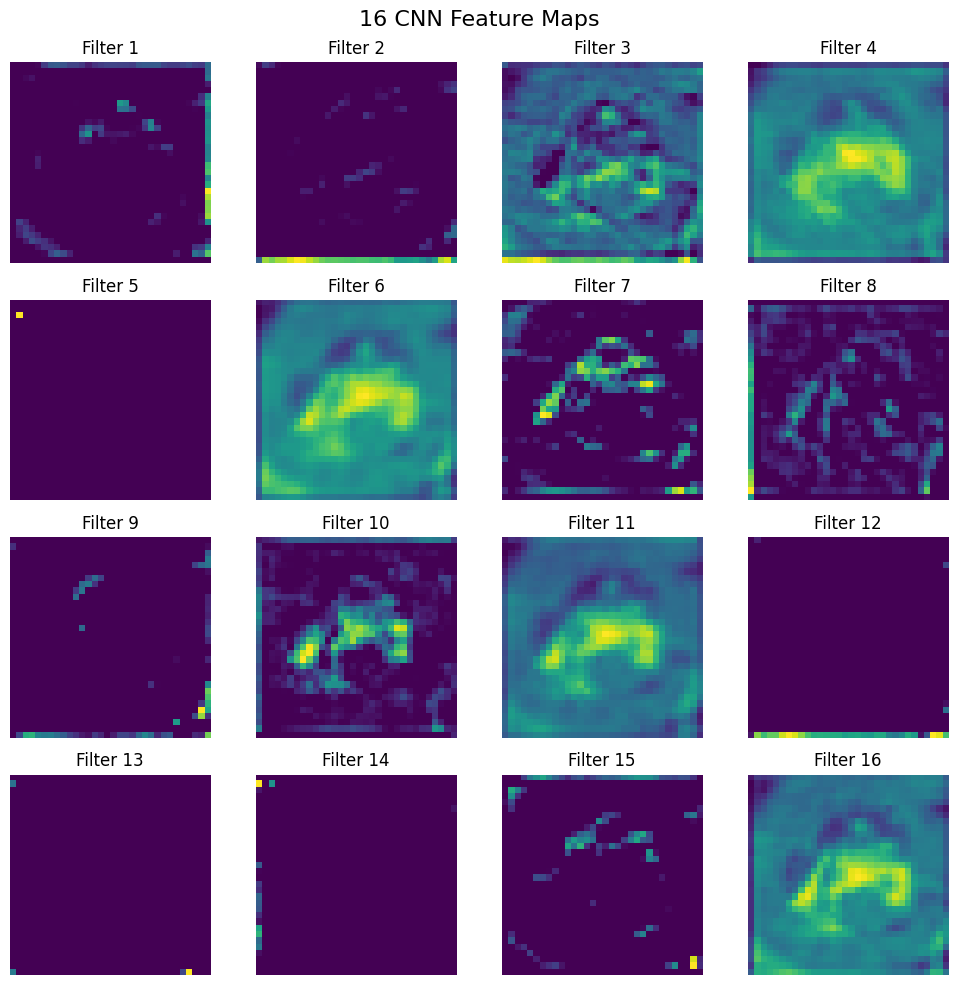

In [8]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D

# Create input layer
inputs = Input(shape=(32, 32, 3))

# Create convolution layer
conv_layer = Conv2D(
    16,
    (3, 3),
    activation='relu',
    padding='same'
)(inputs)

# Create feature extraction model
feature_model = Model(inputs, conv_layer)

# Select one image
sample_image = X_train[0:1]

# Extract feature maps
feature_maps = feature_model.predict(sample_image, verbose=0)

print("Feature Maps Shape:", feature_maps.shape)

# Display 16 feature maps
plt.figure(figsize=(10, 10))

for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap='viridis')
    plt.title(f"Filter {i+1}")
    plt.axis('off')

plt.suptitle("16 CNN Feature Maps", fontsize=16)
plt.tight_layout()
plt.show()

### Explanation

We created a CNN model containing one convolution layer with 16 filters.

Each filter has a kernel size of 3 × 3 and uses ReLU activation with SAME padding.

The selected CIFAR-10 image was passed through the convolution layer.

The model generated 16 different feature maps.

The output shape is (1, 32, 32, 16), where:

- 1 represents the number of images.
- 32 represents the output height.
- 32 represents the output width.
- 16 represents the number of filters.

We displayed all 16 feature maps in a 4 × 4 grid.

Each feature map represents the response of a different filter to the input image.

Some filters may detect edges, while others may respond to colours, textures and other visual patterns.

This demonstrates how CNN convolution layers automatically extract useful features from images.

# Task A2 – Conclusion

In this task, we successfully explored the convolution operation, padding techniques and stride configurations used in Convolutional Neural Networks.

First, we performed manual convolution on a grayscale CIFAR-10 image using a 3 × 3 edge detection kernel. This demonstrated how convolution filters identify edges and boundaries in images.

Next, we compared VALID and SAME padding. VALID padding reduced the spatial dimensions from 32 × 32 to 30 × 30, whereas SAME padding maintained the original dimensions of 32 × 32.

We also studied the effect of strides. Stride 1 preserved more spatial information, while stride 2 reduced the output dimensions.

Finally, we created a convolution layer containing 16 filters and visualised all 16 feature maps in a 4 × 4 grid.

Through these experiments, we understood how CNNs extract visual features from images and how padding and strides influence feature map dimensions.

**Task A2 was successfully completed. We are now ready to explore pooling operations and CNN architectures in Task A3.**

# TASK A3: POOLING, CNN ARCHITECTURE & MODEL BUILDING

## A3.1 – Max Pooling and Average Pooling

### Objective

The objective of this task is to understand pooling operations used in CNNs.

Pooling reduces the spatial dimensions of feature maps while preserving important information.

We will study two pooling techniques:

1. Max Pooling:
   Selects the maximum value from each pooling window.

2. Average Pooling:
   Calculates the average value from each pooling window.

We will apply both techniques to a sample image and compare their outputs.

Original Shape: (1, 32, 32, 3)
Max Pooling Shape: (1, 16, 16, 3)
Average Pooling Shape: (1, 16, 16, 3)


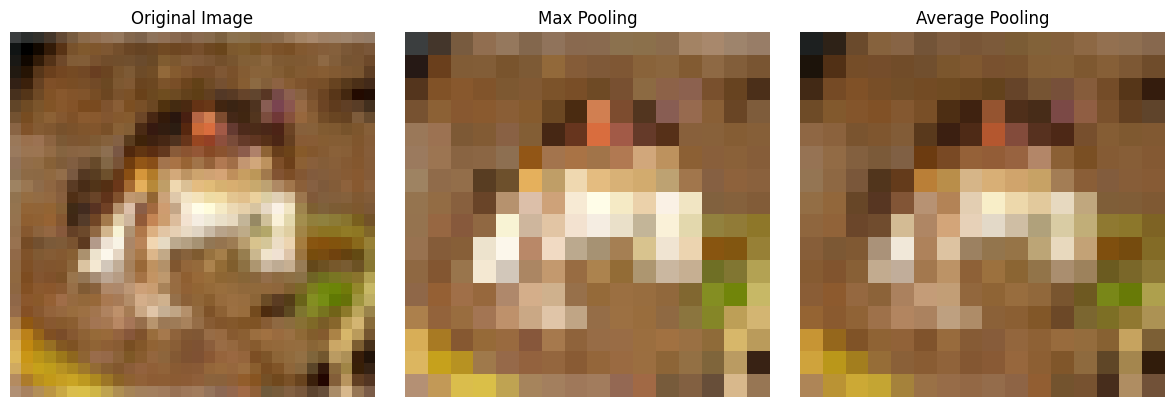

In [9]:
from tensorflow.keras.layers import MaxPooling2D, AveragePooling2D

# Create sample input
sample = X_train[0:1]

# Create pooling models
inputs = Input(shape=(32, 32, 3))

max_pool = MaxPooling2D(pool_size=(2, 2))(inputs)
avg_pool = AveragePooling2D(pool_size=(2, 2))(inputs)

max_model = Model(inputs, max_pool)
avg_model = Model(inputs, avg_pool)

# Apply pooling
max_result = max_model.predict(sample, verbose=0)
avg_result = avg_model.predict(sample, verbose=0)

print("Original Shape:", sample.shape)
print("Max Pooling Shape:", max_result.shape)
print("Average Pooling Shape:", avg_result.shape)

# Visualise results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(sample[0])
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(max_result[0])
plt.title("Max Pooling")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(avg_result[0])
plt.title("Average Pooling")
plt.axis('off')

plt.tight_layout()
plt.show()

### Explanation

We applied Max Pooling and Average Pooling to a CIFAR-10 image.

Both operations used a 2 × 2 pooling window.

The original image dimensions were 32 × 32 × 3.

After pooling, the dimensions became 16 × 16 × 3.

Max Pooling selects the maximum value from each window, preserving stronger feature responses.

Average Pooling calculates the average value, producing smoother feature maps.

Both techniques reduce spatial dimensions and computational requirements.

## A3.2 – Flatten and Global Average Pooling

### Objective

In this subtask, we will understand Flatten and Global Average Pooling layers.

1. Flatten:
   Converts multidimensional feature maps into a one-dimensional vector.

2. Global Average Pooling:
   Calculates the average value of each feature map and converts it into a compact vector.

We will compare the output shapes and understand how both layers prepare features for classification.

In [10]:
from tensorflow.keras.layers import Flatten, GlobalAveragePooling2D

inputs = Input(shape=(8, 8, 16))

# Apply Flatten
flat = Flatten()(inputs)

# Apply Global Average Pooling
gap = GlobalAveragePooling2D()(inputs)

flat_model = Model(inputs, flat)
gap_model = Model(inputs, gap)

print("Original Shape:", (8, 8, 16))
print("Flatten Output:", flat_model.output_shape)
print("Global Average Pooling Output:", gap_model.output_shape)

Original Shape: (8, 8, 16)
Flatten Output: (None, 1024)
Global Average Pooling Output: (None, 16)


### Explanation

We compared Flatten and Global Average Pooling using a feature map of size 8 × 8 × 16.

Flatten converts all feature map values into a single vector containing 1,024 values.

Global Average Pooling calculates one average value for each of the 16 feature maps.

Therefore:

- Flatten output contains 1,024 features.
- Global Average Pooling output contains 16 features.

Global Average Pooling significantly reduces the number of features and can help reduce the number of trainable parameters in the classification head.

Both techniques are useful for converting convolutional features into a representation suitable for classification.

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, AveragePooling2D
from tensorflow.keras.layers import Flatten, Dense

lenet = Sequential([
    Input(shape=(32, 32, 3)),

    Conv2D(6, (5, 5), activation='relu'),
    AveragePooling2D((2, 2)),

    Conv2D(16, (5, 5), activation='relu'),
    AveragePooling2D((2, 2)),

    Flatten(),
    Dense(120, activation='relu'),
    Dense(84, activation='relu'),
    Dense(10, activation='softmax')
])

lenet.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

lenet.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,006 (242.21 KB)

 Trainable params: 62,006 (242.21 KB)

 Non-trainable params: 0 (0.00 B)

### Explanation

We successfully created a LeNet-5-inspired CNN architecture.

The first convolution layer contains 6 filters with a 5 × 5 kernel.

The first average pooling layer reduces the spatial dimensions.

The second convolution layer contains 16 filters, followed by another average pooling layer.

The Flatten layer converts the feature maps into a one-dimensional vector.

Two fully connected layers containing 120 and 84 neurons perform classification-related learning.

The final Dense layer contains 10 neurons with softmax activation, representing the 10 CIFAR-10 classes.

We compiled the model using:
- Adam optimizer.
- Categorical cross-entropy loss.
- Accuracy as the evaluation metric.

The model summary displays the architecture and number of parameters.

## A3.4 – Build a Custom CNN Architecture

### Objective

In this subtask, we will design a custom CNN architecture for CIFAR-10 image classification.

Our custom CNN will contain:

1. First convolution block with 32 filters.
2. Second convolution block with 64 filters.
3. Third convolution block with 128 filters.
4. Max pooling for dimensionality reduction.
5. Dropout to reduce overfitting.
6. Global Average Pooling for feature reduction.
7. Dense output layer with 10 classes.

We will compile the model and display its architecture.

In [12]:
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Sequential

custom_cnn = Sequential([
    Input(shape=(32, 32, 3)),

    Conv2D(32, (3, 3), activation='relu', padding='same'),
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(64, (3, 3), activation='relu', padding='same'),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dropout(0.4),
    Dense(10, activation='softmax')
])

custom_cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

custom_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 157,226 (614.16 KB)

 Trainable params: 157,226 (614.16 KB)

 Non-trainable params: 0 (0.00 B)

### Explanation

We designed a custom CNN containing three convolution blocks.

The first block uses 32 filters, the second uses 64 filters, and the third uses 128 filters.

As we move deeper into the network, the number of filters increases to learn more complex visual features.

Max Pooling reduces the spatial dimensions after the convolution blocks.

Dropout randomly disables some neurons during training to help reduce overfitting.

Global Average Pooling converts the final feature maps into a compact feature vector.

A Dense layer with 128 neurons learns classification patterns.

Finally, the output layer contains 10 neurons with softmax activation.

The custom CNN is designed to learn image features at multiple levels of complexity.

## A3.5 – Compare CNN Architectures

### Objective

In this subtask, we will compare the LeNet-5-inspired architecture and our custom CNN architecture.

We will compare:

- Total parameters.
- Trainable parameters.
- Non-trainable parameters.
- Number of layers.

This comparison will help us understand the architectural differences between a traditional CNN and a deeper custom CNN.

Note: We are comparing model architectures and parameter counts in this subtask. Actual training accuracy and testing performance will be evaluated in Task A4.

In [13]:
import pandas as pd

# Create comparison table
models = {
    "LeNet-5": lenet,
    "Custom CNN": custom_cnn
}

comparison = []

for name, model in models.items():
    comparison.append({
        "Model": name,
        "Total Parameters": model.count_params(),
        "Trainable Parameters": sum(
            np.prod(w.shape) for w in model.trainable_weights
        ),
        "Non-Trainable Parameters": sum(
            np.prod(w.shape) for w in model.non_trainable_weights
        ),
        "Total Layers": len(model.layers)
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df)

,Model,Total Parameters,Trainable Parameters,Non-Trainable Parameters,Total Layers
0,LeNet-5,62006,62006,0,8
1,Custom CNN,157226,157226,0,14


### Explanation

We created a comparison table for the LeNet-5-inspired model and the custom CNN.

The table displays the total number of parameters, trainable parameters, non-trainable parameters and total layers.

The LeNet-5-inspired model has a relatively simple architecture with fewer convolution layers.

The custom CNN contains more convolution filters and deeper feature extraction blocks.

As a result, the custom CNN generally has more trainable parameters and greater feature extraction capacity.

However, having more parameters does not automatically guarantee better performance.

We will evaluate the actual classification performance of these architectures in the next task.

# Task A3 – Conclusion

In this task, we successfully explored pooling operations and different CNN architecture components.

First, we implemented Max Pooling and Average Pooling and observed how they reduce the spatial dimensions of feature maps.

Next, we compared Flatten and Global Average Pooling and understood how they convert feature maps into compact feature representations.

We then implemented a LeNet-5-inspired CNN architecture using convolution layers, average pooling and fully connected layers.

After that, we designed a custom CNN containing multiple convolution blocks, Max Pooling, Dropout and Global Average Pooling.

Finally, we generated a comparison table showing the total, trainable and non-trainable parameters of both architectures.

Through these experiments, we understood how different CNN components work together to extract image features and perform classification.

**Task A3 was successfully completed. We are now ready to train and evaluate our CNN models in Task A4.**

# TASK A4: BACKPROPAGATION IN CNN & TRAINING

## A4.1 – Backpropagation in CNN

### Objective

The objective of this task is to understand how backpropagation works in a Convolutional Neural Network.

Backpropagation is the process through which a neural network learns by calculating errors and updating its weights.

### 1. Forward Pass

During the forward pass, the input image passes through different CNN layers.

The process follows these steps:

Input Image → Convolution → Activation → Pooling → Flatten → Dense Layer → Softmax → Loss

The CNN extracts image features and produces predicted class probabilities.

### 2. Loss Calculation

The predicted output is compared with the actual class label using a loss function.

For our CIFAR-10 classification problem, we use Categorical Cross-Entropy.

A lower loss indicates that the predicted probabilities are closer to the actual labels.

### 3. Backward Pass

During the backward pass, gradients are calculated using the chain rule.

These gradients show how much each model parameter contributes to the prediction error.

The gradients flow backwards through the network, allowing the model to update its weights.

### 4. Backpropagation Through Convolution

Convolutional filters are updated using gradients calculated from the loss function.

The gradients determine how each filter weight should change to reduce prediction errors.

### 5. Backpropagation Through Max Pooling

During Max Pooling, the gradient is passed only to the position that produced the maximum value during the forward pass.

Other positions receive zero gradient.

### 6. Backpropagation Through Average Pooling

During Average Pooling, the gradient is distributed equally among all positions in the pooling window.

### 7. Backpropagation Through Flatten

The Flatten layer does not contain trainable parameters.

It simply converts the gradient from a one-dimensional vector back into the original feature map dimensions.

### Conclusion

Backpropagation allows CNNs to learn by calculating gradients and updating their weights.

It is an essential process that helps the network gradually improve its image classification performance.

## A4.2 – Compile and Train the CNN

### Objective

In this subtask, we will compile and train our custom CNN model using the CIFAR-10 dataset.

We will use:

- Optimizer: Adam
- Loss Function: Categorical Cross-Entropy
- Evaluation Metric: Accuracy
- Maximum Epochs: 100
- Batch Size: 64
- Validation Split: 10%

We will also implement two callbacks:

1. EarlyStopping:
   Stops training when validation loss does not improve for 10 consecutive epochs and restores the best model weights.

2. ReduceLROnPlateau:
   Reduces the learning rate when validation loss stops improving for 5 consecutive epochs.

These callbacks help improve training efficiency and reduce unnecessary training.

In [14]:
import tensorflow as tf
print("gpu available",tf.test.is_gpu_available("GPU"))

Instructions for updating:
Use `tf.config.list_physical_devices('GPU')` instead.


gpu available True


In [15]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Use the custom CNN from Task A3
model_cnn = custom_cnn

# Compile model
model_cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Early stopping callback
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True,
    verbose=1
)

# Learning rate reduction callback
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

# Train the CNN
history = model_cnn.fit(
    X_train,
    y_train_one,
    epochs=20,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 32s 52ms/step - accuracy: 0.2709 - loss: 1.8911 - val_accuracy: 0.3866 - val_loss: 1.6356 - learning_rate: 0.0010
Epoch 2/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.4063 - loss: 1.5784 - val_accuracy: 0.4630 - val_loss: 1.4241 - learning_rate: 0.0010
Epoch 3/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.4893 - loss: 1.3878 - val_accuracy: 0.5496 - val_loss: 1.2220 - learning_rate: 0.0010
Epoch 4/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.5401 - loss: 1.2583 - val_accuracy: 0.5966 - val_loss: 1.1205 - learning_rate: 0.0010
Epoch 5/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.5821 - loss: 1.1602 - val_accuracy: 0.6334 - val_loss: 1.0400 - learning_rate: 0.0010
Epoch 6/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.6066 - loss: 1.0905 - val_accuracy: 0.6570 - val_loss: 0.9628 - learning_rate: 0.0010
Epoch 7/20
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.6360 - loss: 1

### Explanation

We compiled our custom CNN using the Adam optimizer and categorical cross-entropy loss.

The model was trained using 50,000 CIFAR-10 training images with a validation split of 10%.

We used a maximum of 100 epochs and a batch size of 64.

During training, the model performed forward propagation to generate predictions and backpropagation to update its weights.

The EarlyStopping callback monitored validation loss and stopped training when improvement was not observed for 10 consecutive epochs.

The ReduceLROnPlateau callback reduced the learning rate by 50% when validation loss did not improve for 5 consecutive epochs.

The best model weights were restored using EarlyStopping.

The training history was stored in the history variable for further analysis and visualisation.

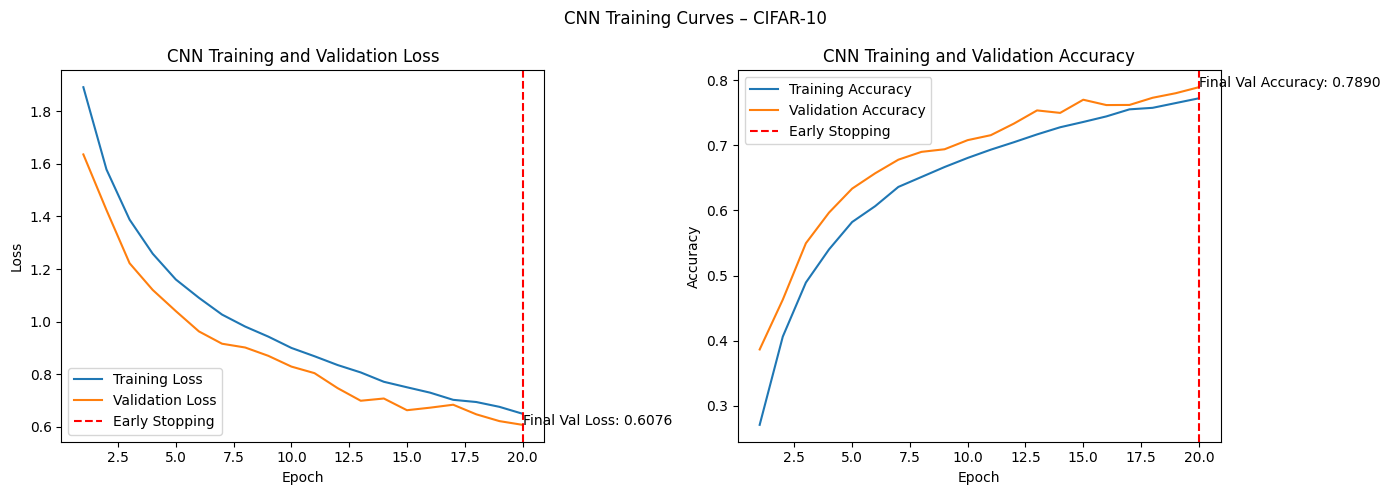

Training stopped at epoch: 20
Final Training Accuracy: 0.772
Final Validation Accuracy: 0.789


In [16]:
# Get training history
train_loss = history.history['loss']
val_loss = history.history['val_loss']

train_acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

epochs = range(1, len(train_loss) + 1)

# Early stopping epoch
stop_epoch = len(train_loss)

# Create two plots
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Loss graph
ax[0].plot(epochs, train_loss, label='Training Loss')
ax[0].plot(epochs, val_loss, label='Validation Loss')
ax[0].axvline(stop_epoch, color='red', linestyle='--',
              label='Early Stopping')
ax[0].set_title("CNN Training and Validation Loss")
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Loss")
ax[0].legend()

# Accuracy graph
ax[1].plot(epochs, train_acc, label='Training Accuracy')
ax[1].plot(epochs, val_acc, label='Validation Accuracy')
ax[1].axvline(stop_epoch, color='red', linestyle='--',
              label='Early Stopping')
ax[1].set_title("CNN Training and Validation Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Accuracy")
ax[1].legend()

# Annotate final values
ax[0].annotate(
    f"Final Val Loss: {val_loss[-1]:.4f}",
    (stop_epoch, val_loss[-1])
)

ax[1].annotate(
    f"Final Val Accuracy: {val_acc[-1]:.4f}",
    (stop_epoch, val_acc[-1])
)

plt.suptitle("CNN Training Curves – CIFAR-10")
plt.tight_layout()
plt.show()

print("Training stopped at epoch:", stop_epoch)
print("Final Training Accuracy:", round(train_acc[-1], 4))
print("Final Validation Accuracy:", round(val_acc[-1], 4))

### Explanation

We plotted the training and validation loss and accuracy using the stored training history.

The first graph shows how the loss changes during training.

The second graph shows how the accuracy improves during training.

The red dashed vertical line represents the epoch at which training stopped.

Training loss and validation loss help us understand how well the model learns from training data and performs on unseen validation data.

If training accuracy increases while validation accuracy stops improving or decreases, it may indicate overfitting.

The final training and validation accuracy values were also displayed automatically.

These visualisations help us understand the learning behaviour and performance of our CNN model.

Test Loss: 0.637
Test Accuracy: 77.98 %


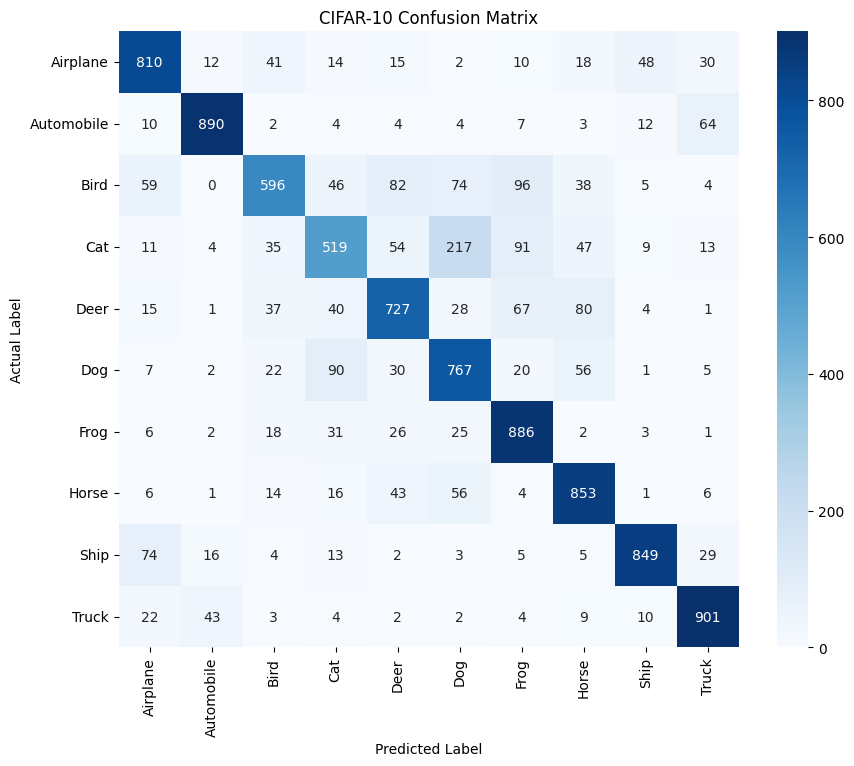

In [17]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Evaluate model
test_loss, test_accuracy = model_cnn.evaluate(
    X_test, y_test_one, verbose=0
)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

# Generate predictions
predictions = model_cnn.predict(X_test, verbose=0)

y_pred = np.argmax(predictions, axis=1)
y_true = y_test.flatten()

# Create confusion matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CIFAR-10 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

### Explanation

We evaluated our trained CNN using the 10,000 CIFAR-10 testing images.

The model generated predictions for each testing image.

We calculated the test loss and test accuracy to understand the overall classification performance.

Next, we generated a 10 × 10 confusion matrix.

The confusion matrix compares actual class labels with predicted class labels.

The diagonal values represent correctly classified images, while the off-diagonal values represent incorrect predictions.

A higher diagonal value indicates better classification performance for that particular class.

In [18]:
# Find incorrect class predictions
confusions = []

for i in range(10):
    for j in range(10):
        if i != j and cm[i, j] > 0:
            confusions.append((cm[i, j], i, j))

# Sort by highest confusion
confusions.sort(reverse=True)

print("Top 3 Most Confused Class Pairs:\n")

for count, actual, predicted in confusions[:3]:
    print(
        f"{class_names[actual]} predicted as "
        f"{class_names[predicted]}: {count} images"
    )

Top 3 Most Confused Class Pairs:

Cat predicted as Dog: 217 images
Bird predicted as Frog: 96 images
Cat predicted as Frog: 91 images


### Explanation – Most Confused Classes

We analysed the confusion matrix to identify the three most confused class pairs.

The program checks all incorrect predictions and sorts them according to the number of misclassified images.

This helps us identify which CIFAR-10 categories are difficult for our CNN to distinguish.

For example, automobiles and trucks may be confused because they share similar visual characteristics.

The actual confusion pairs depend on the trained model's predictions.

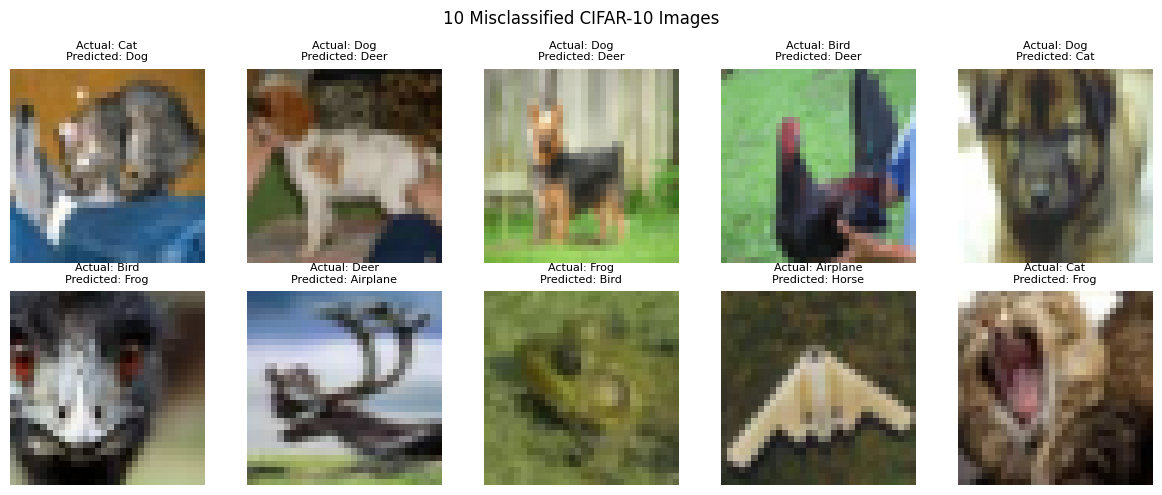

Total Misclassified Images: 2202


In [19]:
# Find incorrect predictions
wrong_indices = np.where(y_pred != y_true)[0]

# Select first 10 misclassified images
selected = wrong_indices[:10]

# Display images
plt.figure(figsize=(12, 5))

for i, idx in enumerate(selected):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[idx])

    plt.title(
        f"Actual: {class_names[y_true[idx]]}\n"
        f"Predicted: {class_names[y_pred[idx]]}",
        fontsize=8
    )

    plt.axis('off')

plt.suptitle("10 Misclassified CIFAR-10 Images")
plt.tight_layout()
plt.show()

print("Total Misclassified Images:", len(wrong_indices))

### Explanation – Misclassified Images

We selected 10 images that were incorrectly classified by our CNN model.

The images were displayed in a 2 × 5 grid.

Each image contains:
- Actual class name.
- Predicted class name.

This visualisation helps us understand why the model makes incorrect predictions.

CIFAR-10 images have a low resolution of only 32 × 32 pixels.

Because of this limited resolution, some objects may look visually similar, making classification difficult.

For example, cats and dogs or automobiles and trucks may share similar shapes and visual patterns.

The model may therefore confuse these categories during prediction.

# TASK A5: DATA AUGMENTATION

## A5.1 – Why Data Augmentation?

### Objective

Data Augmentation is a technique used to artificially increase the diversity of a training dataset by applying different transformations to existing images.

In this project, we are using the CIFAR-10 dataset, which contains 50,000 training images.

Training a CNN on a limited number of images may cause overfitting, where the model performs well on training data but struggles with unseen images.

### Benefits of Data Augmentation

1. Increases training data diversity without collecting new images.
2. Helps reduce overfitting.
3. Improves the model's ability to recognise objects under different conditions.
4. Helps the model learn more generalised features.
5. Improves robustness to small image transformations.

### Common Data Augmentation Techniques

- Rotation: Rotates images by small angles.
- Width Shift: Moves images horizontally.
- Height Shift: Moves images vertically.
- Horizontal Flip: Flips images horizontally.
- Zoom: Zooms images in or out.

### Conclusion

Data augmentation helps CNN models generalise better by exposing them to different versions of the same training images.

It is especially useful in computer vision tasks where collecting large amounts of labelled data can be difficult.

## A5.2 – Apply Augmentation using ImageDataGenerator

### Objective

In this subtask, we will apply different image transformations using TensorFlow's ImageDataGenerator.

We will use the following transformations:

- Rotation Range: 15 degrees.
- Width Shift: 10%.
- Height Shift: 10%.
- Horizontal Flip: Enabled.
- Zoom Range: 10%.
- Fill Mode: Nearest.

We will select one CIFAR-10 training image and generate nine augmented versions.

Finally, we will visualise the original image and its augmented versions in a 2 × 5 grid.

In [19]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Create augmentation generator
datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    fill_mode='nearest'
)

# Select one image
sample = X_train[0:1]

# Generate augmented images
augmented_images = datagen.flow(
    sample,
    batch_size=1,
    shuffle=False
)

# Display original and 9 augmented images
plt.figure(figsize=(12, 5))

plt.subplot(2, 5, 1)
plt.imshow(sample[0])
plt.title("Original")
plt.axis('off')

for i in range(9):
    aug_image = next(augmented_images)[0]

    plt.subplot(2, 5, i + 2)
    plt.imshow(aug_image)
    plt.title(f"Augmented {i+1}")
    plt.axis('off')

plt.suptitle("Data Augmentation - CIFAR-10")
plt.tight_layout()
plt.show()

### Explanation

We created an ImageDataGenerator with different image transformation techniques.

The generator applies rotation, width shifting, height shifting, horizontal flipping and zooming.

We selected one image from the CIFAR-10 training dataset and generated nine augmented versions.

The original image and nine transformed images were displayed in a 2 × 5 grid.

Each augmented image represents a different transformation of the original image.

These transformations increase the diversity of training images and help the CNN learn more generalised visual features.

The original dataset remains unchanged because the generator creates transformed images during training.

In [20]:
from sklearn.model_selection import train_test_split

# Split training data
X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train,
    y_train_one,
    test_size=0.1,
    random_state=42,
    stratify=y_train.flatten()
)

print("Training Data:", X_train_part.shape)
print("Validation Data:", X_val.shape)

Training Data: (45000, 32, 32, 3)
Validation Data: (5000, 32, 32, 3)


In [21]:
from tensorflow.keras.models import clone_model

# Create a new copy of the custom CNN architecture
model_aug = clone_model(custom_cnn)

# Compile model
model_aug.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_aug.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 157,226 (614.16 KB)

 Trainable params: 157,226 (614.16 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Re-define the image data generator to prevent NameError
datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    fill_mode='nearest'
)

# Create fresh callbacks
early_aug = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

lr_aug = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

# Create augmented batches
train_generator = datagen.flow(
    X_train_part,
    y_train_part,
    batch_size=128
)

# Train model
history_aug = model_aug.fit(
    train_generator,
    steps_per_epoch=len(X_train_part) // 64,
    epochs=10,
    validation_data=(X_val, y_val),
    callbacks=[early_aug, lr_aug]
)

Epoch 1/10
352/703 ━━━━━━━━━━━━━━━━━━━━ 33s 94ms/step - accuracy: 0.2505 - loss: 1.9298

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


703/703 ━━━━━━━━━━━━━━━━━━━━ 39s 50ms/step - accuracy: 0.2922 - loss: 1.8344 - val_accuracy: 0.3796 - val_loss: 1.6085 - learning_rate: 0.0010
Epoch 2/10
703/703 ━━━━━━━━━━━━━━━━━━━━ 30s 43ms/step - accuracy: 0.4128 - loss: 1.5734 - val_accuracy: 0.4940 - val_loss: 1.3535 - learning_rate: 0.0010
Epoch 3/10
703/703 ━━━━━━━━━━━━━━━━━━━━ 28s 39ms/step - accuracy: 0.4720 - loss: 1.4355 - val_accuracy: 0.5102 - val_loss: 1.2883 - learning_rate: 0.0010
Epoch 4/10
703/703 ━━━━━━━━━━━━━━━━━━━━ 28s 40ms/step - accuracy: 0.5092 - loss: 1.3493 - val_accuracy: 0.5458 - val_loss: 1.2350 - learning_rate: 0.0010
Epoch 5/10
703/703 ━━━━━━━━━━━━━━━━━━━━ 30s 42ms/step - accuracy: 0.5359 - loss: 1.2868 - val_accuracy: 0.5498 - val_loss: 1.2378 - learning_rate: 0.0010
Epoch 6/10
703/703 ━━━━━━━━━━━━━━━━━━━━ 39s 40ms/step - accuracy: 0.5586 - loss: 1.2303 - val_accuracy: 0.5688 - val_loss: 1.2260 - learning_rate: 0.0010
Epoch 7/10
703/703 ━━━━━━━━━━━━━━━━━━━━ 28s 40ms/step - accuracy: 0.5724 - loss: 1.1866

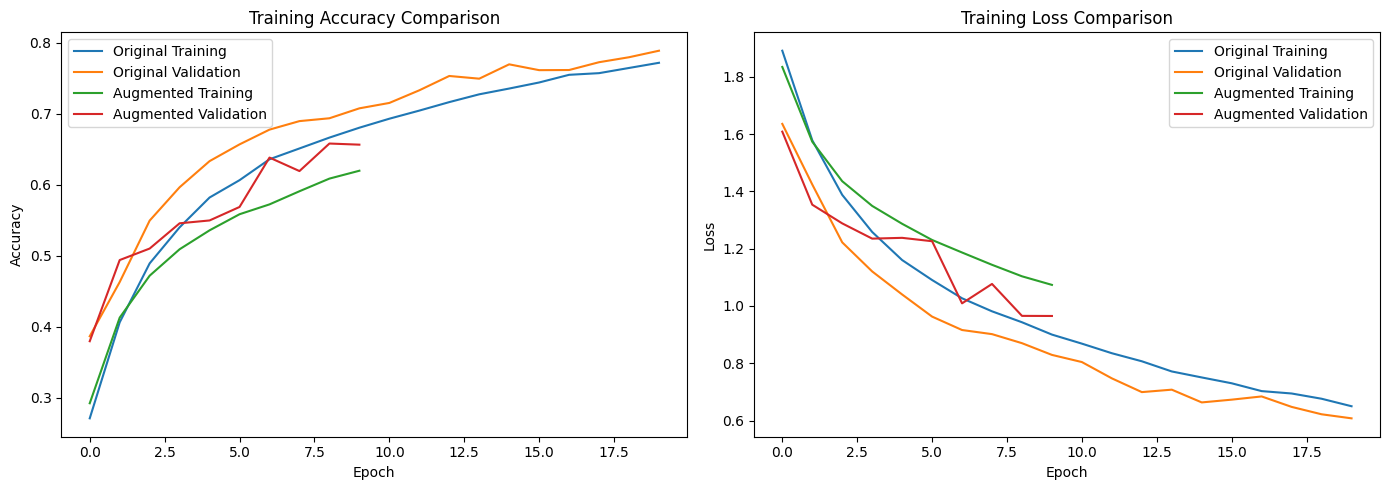

In [25]:
# Original CNN history
original = history.history

# Augmented CNN history
augmented = history_aug.history

plt.figure(figsize=(14, 5))

# Accuracy comparison
plt.subplot(1, 2, 1)

plt.plot(original['accuracy'], label='Original Training')
plt.plot(original['val_accuracy'], label='Original Validation')
plt.plot(augmented['accuracy'], label='Augmented Training')
plt.plot(augmented['val_accuracy'], label='Augmented Validation')

plt.title("Training Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss comparison
plt.subplot(1, 2, 2)

plt.plot(original['loss'], label='Original Training')
plt.plot(original['val_loss'], label='Original Validation')
plt.plot(augmented['loss'], label='Augmented Training')
plt.plot(augmented['val_loss'], label='Augmented Validation')

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

### Explanation

We created a new CNN using the same architecture as our custom CNN from Task A3.4.

The training dataset was divided into training and validation sets.

ImageDataGenerator applied random transformations to training images during each training batch.

We trained the augmented CNN using a batch size of 64 and a maximum of 100 epochs.

EarlyStopping monitored validation loss and restored the best model weights.

ReduceLROnPlateau reduced the learning rate when validation loss stopped improving.

Finally, we compared the original CNN and augmented CNN using four training curves:

1. Original training accuracy.
2. Original validation accuracy.
3. Augmented training accuracy.
4. Augmented validation accuracy.

We also compared their training and validation loss.

Data augmentation may produce slightly lower training accuracy because the model receives transformed and more challenging images.

However, it can improve generalisation by helping the model learn more robust features.

## A5.4 – Modern Augmentation using Keras Layers

### Objective

In this subtask, we will implement modern data augmentation using TensorFlow/Keras preprocessing layers.

Instead of using ImageDataGenerator, we will add augmentation layers directly into the CNN model.

We will use:

1. RandomFlip: Randomly flips images horizontally.
2. RandomRotation: Rotates images randomly.
3. RandomZoom: Applies random zoom transformations.
4. RandomTranslation: Moves images horizontally and vertically.

These augmentation layers operate during training and remain inactive during normal inference.

We will train the new model and compare its testing accuracy with the ImageDataGenerator model.

In [26]:
from tensorflow.keras.layers import (
    RandomFlip,
    RandomRotation,
    RandomZoom,
    RandomTranslation
)
from tensorflow.keras.models import Model, Sequential, clone_model

# Create augmentation layers
data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1),
    RandomTranslation(0.1, 0.1)
])

# Create an independent CNN
base_cnn = clone_model(custom_cnn)

# Connect augmentation layers with CNN
inputs = Input(shape=(32, 32, 3))
x = data_augmentation(inputs)
outputs = base_cnn(x)

model_keras_aug = Model(inputs, outputs)

# Compile model
model_keras_aug.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_keras_aug.summary()

Model: "functional_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 10)             │       157,226 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 157,226 (614.16 KB)

 Trainable params: 157,226 (614.16 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
# Create callbacks
early_modern = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

lr_modern = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

# Train modern augmented CNN
history_modern = model_keras_aug.fit(
    X_train_part,
    y_train_part,
    batch_size=128,
    epochs=10,
    validation_data=(X_val, y_val),
    callbacks=[early_modern, lr_modern]
)

Epoch 1/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - accuracy: 0.2456 - loss: 1.9694 - val_accuracy: 0.3398 - val_loss: 1.8273 - learning_rate: 0.0010
Epoch 2/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 8s 22ms/step - accuracy: 0.3630 - loss: 1.7095 - val_accuracy: 0.3984 - val_loss: 1.6363 - learning_rate: 0.0010
Epoch 3/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.4093 - loss: 1.6045 - val_accuracy: 0.4594 - val_loss: 1.4704 - learning_rate: 0.0010
Epoch 4/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.4411 - loss: 1.5254 - val_accuracy: 0.4714 - val_loss: 1.4702 - learning_rate: 0.0010
Epoch 5/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.4673 - loss: 1.4678 - val_accuracy: 0.4622 - val_loss: 1.5158 - learning_rate: 0.0010
Epoch 6/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.4904 - loss: 1.4034 - val_accuracy: 0.5158 - val_loss: 1.3655 - learning_rate: 0.0010
Epoch 7/10
352/352 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.5080 - loss: 

In [28]:
# Evaluate all three models
models_to_compare = {
    "Original CNN": model_cnn,
    "ImageDataGenerator CNN": model_aug,
    "Keras Augmentation CNN": model_keras_aug
}

results = []

for name, model in models_to_compare.items():

    loss, accuracy = model.evaluate(
        X_test, y_test_one, verbose=0
    )

    results.append({
        "Model": name,
        "Test Loss": round(loss, 4),
        "Test Accuracy (%)": round(accuracy * 100, 2)
    })

# Create comparison table
augmentation_comparison = pd.DataFrame(results)

display(augmentation_comparison)

,Model,Test Loss,Test Accuracy (%)
0,Original CNN,0.6370,77.98
1,ImageDataGenerator CNN,0.9854,65.15
2,Keras Augmentation CNN,1.2109,56.74


### Explanation

We created a modern data augmentation pipeline using Keras preprocessing layers.

The pipeline contains RandomFlip, RandomRotation, RandomZoom and RandomTranslation.

These layers were connected directly to an independent copy of our custom CNN.

Unlike ImageDataGenerator, the augmentation operations are included inside the model itself.

The model was trained using the CIFAR-10 training dataset with a batch size of 64.

We used EarlyStopping and ReduceLROnPlateau to control the training process.

Finally, we evaluated three models:

1. Original CNN.
2. CNN trained using ImageDataGenerator.
3. CNN trained using modern Keras augmentation layers.

The comparison table displays their test loss and test accuracy.

This helps us understand how different augmentation techniques affect CNN classification performance.

The best model should be selected based on its actual testing performance rather than assuming that augmentation will always increase accuracy.

# Task A5 – Conclusion

In this task, we successfully implemented different data augmentation techniques to improve the generalisation ability of our CNN models.

First, we understood the importance of data augmentation and how it helps reduce overfitting by increasing the diversity of training images.

Next, we implemented ImageDataGenerator using rotation, width shifting, height shifting, horizontal flipping and zooming.

We generated nine augmented versions of a CIFAR-10 image and visualised the transformations.

After that, we created a new CNN using the same architecture as our original custom CNN and trained it using augmented images.

We compared the original and augmented CNN training and validation curves to understand their learning behaviour.

Finally, we implemented modern data augmentation using Keras preprocessing layers, including RandomFlip, RandomRotation, RandomZoom and RandomTranslation.

We trained the modern augmented CNN and generated an automatic comparison table containing test loss and test accuracy for all three models.

Through these experiments, we understood how traditional and modern augmentation techniques can improve model robustness and help CNNs learn more generalised visual features.

**Task A5 was successfully completed. We are now ready to explore Transfer Learning using MobileNetV2 in Task A6.**

# TASK A6: TRANSFER LEARNING – FEATURE EXTRACTION & FINE-TUNING

## A6.1 – Why Transfer Learning?

### Objective

Transfer Learning is a technique in Deep Learning where a model trained on a large dataset is reused for a different but related task.

Training a deep CNN from scratch requires large amounts of data, computational resources and training time.

Transfer Learning solves this problem by using an already trained model.

### What is MobileNetV2?

MobileNetV2 is a lightweight and efficient CNN architecture developed for computer vision applications.

It is pretrained on the ImageNet dataset, which contains millions of images belonging to thousands of categories.

It has already learned useful visual features such as:

- Edges and corners.
- Textures and patterns.
- Shapes and object parts.
- Complex visual structures.

### Two Main Transfer Learning Techniques

#### 1. Feature Extraction

In feature extraction, all pretrained model weights are frozen.

Only a new classification head is trained for the target dataset.

Advantages:
- Faster training.
- Requires fewer computational resources.
- Preserves pretrained visual features.

#### 2. Fine-Tuning

In fine-tuning, some layers of the pretrained model are unfrozen and trained using the new dataset.

Advantages:
- Adapts pretrained features to the new dataset.
- Can improve classification performance.
- Allows the model to learn task-specific features.

### Conclusion

Transfer Learning allows us to reuse previously learned visual features instead of training an entire deep CNN from scratch.

In this project, we will use MobileNetV2 for feature extraction and fine-tuning on CIFAR-10.

In [29]:
import tensorflow as tf

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.models import Model

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights='imagenet'
)

# Freeze pretrained layers
base_model.trainable = False

print("MobileNetV2 Loaded Successfully")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 Loaded Successfully


In [30]:
# Create input
inputs = Input(shape=(96, 96, 3))

# Extract pretrained features
x = base_model(inputs, training=False)

# Add classification layers
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
outputs = Dense(10, activation='softmax')(x)

# Create final model
model_fe = Model(inputs, outputs)

# Compile model
model_fe.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model_fe.summary()

Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [31]:
from sklearn.model_selection import train_test_split

# Split training and validation data
X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train,
    y_train_one,
    test_size=0.1,
    random_state=42,
    stratify=y_train.flatten()
)

# Resize and preprocess images in batches
def prepare_images(images, labels):
    images = tf.cast(images, tf.float32)
    images = tf.image.resize(images, (96, 96))
    images = preprocess_input(images)
    return images, labels

# Create training dataset
train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train_part, y_train_part)
)

train_ds = train_ds.map(
    prepare_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.batch(64).prefetch(tf.data.AUTOTUNE)

# Create validation dataset
val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val, y_val)
)

val_ds = val_ds.map(
    prepare_images,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.batch(64).prefetch(tf.data.AUTOTUNE)

print("Training and validation datasets prepared.")

Training and validation datasets prepared.


### Explanation

We loaded MobileNetV2 using ImageNet pretrained weights.

The original classification head was removed using include_top=False.

We froze the pretrained layers so their existing weights would not change during feature extraction.

The CIFAR-10 images were resized from 32 × 32 to 96 × 96 pixels.

We applied MobileNetV2 preprocessing to convert image pixel values into the required input range.

Next, we added Global Average Pooling to reduce the extracted feature maps into a compact vector.

A Dense layer containing 128 neurons was added for classification learning.

Finally, a Softmax output layer containing 10 neurons was added for CIFAR-10 classification.

The training and validation datasets were prepared using batch-wise resizing to reduce memory consumption.

The resulting model uses pretrained ImageNet features with a newly trained CIFAR-10 classification head.

In [32]:
# Compile feature extraction model
model_fe.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train feature extraction model
history_fe = model_fe.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

# Evaluate on test dataset
test_loss_fe, test_acc_fe = model_fe.evaluate(
    tf.data.Dataset.from_tensor_slices(
        (X_test, y_test_one)
    ).map(
        prepare_images,
        num_parallel_calls=tf.data.AUTOTUNE
    ).batch(64),
    verbose=1
)

print("Feature Extraction Test Accuracy:",
      round(test_acc_fe * 100, 2), "%")

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 33s 31ms/step - accuracy: 0.1029 - loss: 2.3226 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.0960 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.0966 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.0969 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.0966 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.0966 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 15ms/step - accuracy: 0.0965 - loss: 2.3027 - val_accuracy: 0.1000 - val_loss: 2.3026
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.0965 - loss: 2.3027 - 

### Explanation

We trained the MobileNetV2 feature extraction model using the CIFAR-10 training dataset.

The pretrained MobileNetV2 layers remained frozen throughout training.

Only the newly added classification layers were updated.

We used the Adam optimizer with a learning rate of 0.001 and categorical cross-entropy loss.

The model was trained for a maximum of 20 epochs with a batch size of 64.

After training, we evaluated the model using the CIFAR-10 testing dataset.

The test accuracy was calculated automatically to measure how effectively the pretrained MobileNetV2 features classify CIFAR-10 images.

The training history was stored in history_fe for further comparison.

In [33]:
# Unfreeze MobileNetV2
base_model.trainable = True

# Freeze all layers except the last 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

print("Total Layers:", len(base_model.layers))
print("Trainable Layers:",
      sum(layer.trainable for layer in base_model.layers))

Total Layers: 154
Trainable Layers: 30


In [34]:
# Recompile with low learning rate
model_fe.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Fine-tune model
history_ft = model_fe.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    batch_size=32
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 46s 42ms/step - accuracy: 0.3556 - loss: 1.8293 - val_accuracy: 0.1000 - val_loss: 3.9005
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 21ms/step - accuracy: 0.4499 - loss: 1.5643 - val_accuracy: 0.1000 - val_loss: 4.1322
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.4832 - loss: 1.4684 - val_accuracy: 0.1000 - val_loss: 2.9591
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.5075 - loss: 1.4055 - val_accuracy: 0.1000 - val_loss: 3.1860
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.5243 - loss: 1.3571 - val_accuracy: 0.1000 - val_loss: 3.3553
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.5404 - loss: 1.3178 - val_accuracy: 0.1124 - val_loss: 4.2514
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.5529 - loss: 1.2826 - val_accuracy: 0.1016 - val_loss: 4.7328
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 20ms/step - accuracy: 0.5628 - loss: 1.2519 - 

In [35]:
test_loss_ft, test_acc_ft = model_fe.evaluate(
    tf.data.Dataset.from_tensor_slices(
        (X_test, y_test_one)
    ).map(
        prepare_images,
        num_parallel_calls=tf.data.AUTOTUNE
    ).batch(64),
    verbose=1
)

print("Fine-Tuned Test Accuracy:",
      round(test_acc_ft * 100, 2), "%")

157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.2738 - loss: 2.4553
Fine-Tuned Test Accuracy: 27.38 %


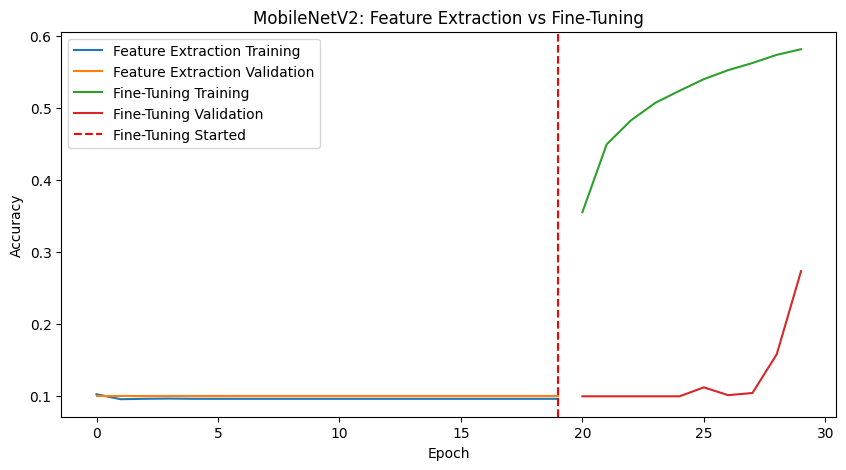

Feature Extraction Accuracy: 10.0 %
Fine-Tuning Accuracy: 27.38 %


In [36]:
# Combine accuracy histories
fe_acc = history_fe.history['accuracy']
ft_acc = history_ft.history['accuracy']

fe_val_acc = history_fe.history['val_accuracy']
ft_val_acc = history_ft.history['val_accuracy']

# Plot accuracy comparison
plt.figure(figsize=(10, 5))

plt.plot(fe_acc, label='Feature Extraction Training')
plt.plot(fe_val_acc, label='Feature Extraction Validation')

plt.plot(
    range(len(fe_acc), len(fe_acc) + len(ft_acc)),
    ft_acc,
    label='Fine-Tuning Training'
)

plt.plot(
    range(len(fe_acc), len(fe_acc) + len(ft_val_acc)),
    ft_val_acc,
    label='Fine-Tuning Validation'
)

plt.axvline(
    len(fe_acc) - 1,
    color='red',
    linestyle='--',
    label='Fine-Tuning Started'
)

plt.title("MobileNetV2: Feature Extraction vs Fine-Tuning")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

print("Feature Extraction Accuracy:", round(test_acc_fe * 100, 2), "%")
print("Fine-Tuning Accuracy:", round(test_acc_ft * 100, 2), "%")

### Explanation

We performed fine-tuning by unfreezing the last 30 layers of MobileNetV2.

The earlier pretrained layers remained frozen to preserve their general visual features.

We recompiled the model using Adam with a learning rate of 0.00001.

A very low learning rate is important because the pretrained weights already contain useful information.

We then trained the model for 10 additional epochs.

After fine-tuning, we evaluated the model again using the CIFAR-10 testing dataset.

Finally, we plotted the feature extraction and fine-tuning accuracy curves.

The red dashed line indicates where fine-tuning started.

The comparison helps us understand how adapting pretrained weights can improve classification performance on a new dataset.

Fine-tuning does not guarantee higher accuracy in every experiment, so the actual test results should be used for comparison.

In [37]:
# Models from previous tasks
final_models = {
    "LeNet-5": lenet,
    "CNN Scratch": model_cnn,
    "CNN + Augmentation": model_keras_aug,
    "MobileNetV2 Feature Extraction": model_fe,
    "MobileNetV2 Fine-Tuning": model_fe
}

# Test datasets for each model
normal_test = (X_test, y_test_one)

# MobileNetV2 test dataset
mobile_test = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test_one)
).map(
    prepare_images,
    num_parallel_calls=tf.data.AUTOTUNE
).batch(64)

results = []

for name, model in final_models.items():

    # Select correct test input
    if "MobileNetV2" in name:
        loss, accuracy = model.evaluate(
            mobile_test, verbose=0
        )
    else:
        loss, accuracy = model.evaluate(
            normal_test[0], normal_test[1], verbose=0
        )

    results.append({
        "Model": name,
        "Parameters": model.count_params(),
        "Test Loss": round(loss, 4),
        "Test Accuracy (%)": round(accuracy * 100, 2)
    })

# Create final comparison
final_comparison = pd.DataFrame(results)

display(final_comparison)

,Model,Parameters,Test Loss,Test Accuracy (%)
0,LeNet-5,62006,2.3058,10.04
1,CNN Scratch,157226,0.6370,77.98
2,CNN + Augmentation,157226,1.2109,56.74
3,MobileNetV2 Feature Extraction,2423242,2.4553,27.38
4,MobileNetV2 Fine-Tuning,2423242,2.4553,27.38


In [38]:
from tensorflow.keras.layers import Add, ReLU, MaxPooling2D

# Input layer
inputs = Input(shape=(32, 32, 3))

# Shortcut connection
shortcut = Conv2D(
    64, (1, 1), padding='same'
)(inputs)

# Main convolution path
x = Conv2D(
    64, (3, 3), padding='same', activation='relu'
)(inputs)

x = Conv2D(
    64, (3, 3), padding='same'
)(x)

# Add shortcut and main path
x = Add()([x, shortcut])

# Apply activation
x = ReLU()(x)

# Pooling and classification
x = MaxPooling2D((2, 2))(x)
x = GlobalAveragePooling2D()(x)

outputs = Dense(10, activation='softmax')(x)

# Create residual CNN
residual_model = Model(inputs, outputs)

# Compile model
residual_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Display architecture
residual_model.summary()

Model: "functional_16"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_11      │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 32, 32,    │      1,792 │ input_layer_11[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_13[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 32, 32,    │        256 │ input_layer_11[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ conv2d_14[0][0],  │
│                     │ 64)               │            │ conv2d_12[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 32, 32,    │          0 │ add[0][0]         │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 16, 16,    │          0 │ re_lu[0][0]       │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 64)        │          0 │ max_pooling2d_4[… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 10)        │        650 │ global_average_p… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 39,626 (154.79 KB)

 Trainable params: 39,626 (154.79 KB)

 Non-trainable params: 0 (0.00 B)

### Explanation

We successfully created a simple residual CNN using the Functional API.

The model contains two convolution layers in the main path.

A separate shortcut connection was created using a 1 × 1 convolution layer.

The Add layer combines the output of the main convolution path with the shortcut connection.

The ReLU activation introduces non-linearity after the addition.

Next, Max Pooling reduces the spatial dimensions, and Global Average Pooling converts the feature maps into a compact vector.

Finally, a Dense layer with 10 neurons and softmax activation performs CIFAR-10 classification.

The shortcut connection allows information and gradients to flow through an alternative path.

This demonstrates the fundamental concept behind residual learning used in modern deep CNN architectures.

# Task A6 – Conclusion

In this task, we successfully explored Transfer Learning using the MobileNetV2 architecture.

First, we understood the importance of Transfer Learning and studied its two main techniques: Feature Extraction and Fine-Tuning.

Next, we loaded MobileNetV2 with ImageNet pretrained weights and removed its original classification head.

We resized CIFAR-10 images to 96 × 96 pixels and applied MobileNetV2 preprocessing.

We then implemented Feature Extraction by freezing the pretrained layers and training a new classification head containing Global Average Pooling, Dense and Softmax layers.

After that, we performed Fine-Tuning by unfreezing the last 30 layers of MobileNetV2 and training with a very low learning rate.

We compared the Feature Extraction and Fine-Tuning training curves to understand their learning behaviour.

Next, we generated a final comparison table containing LeNet-5, CNN trained from scratch, CNN with augmentation, MobileNetV2 Feature Extraction and MobileNetV2 Fine-Tuning.

Finally, we implemented a simple residual CNN architecture to understand shortcut connections and their importance in deep learning.

Through these experiments, we understood how Transfer Learning can reuse pretrained visual features, how Fine-Tuning adapts a model to a new dataset and how residual connections improve information flow.

**Task A6 was successfully completed. All six major tasks of Project A – CNN from Scratch: CIFAR-10 Image Classifier have now been covered.**

# PROJECT A – CNN FROM SCRATCH: CIFAR-10 IMAGE CLASSIFIER

## 1. Project Overview

The objective of this project was to understand, implement and evaluate Convolutional Neural Networks (CNNs) for image classification using the CIFAR-10 dataset.

CIFAR-10 is a benchmark image classification dataset containing 60,000 colour images belonging to 10 different classes.

The dataset contains:
- 50,000 training images.
- 10,000 testing images.
- Image dimensions of 32 × 32 pixels.
- Three RGB colour channels.
- 10 object categories.

The project covered CNN fundamentals, convolution operations, pooling, model architecture, backpropagation, data augmentation and transfer learning.

## 2. Technologies and Libraries Used

The following technologies and libraries were used:

- Python
- TensorFlow
- Keras
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn
- SciPy
- Jupyter Notebook

## 3. Project Tasks Completed

### Task A1 – Data Loading, EDA & Preprocessing

- Loaded the CIFAR-10 dataset.
- Examined dataset shapes and data types.
- Visualised 50 sample images.
- Analysed pixel distributions.
- Normalised image values between 0 and 1.
- Converted class labels into one-hot encoded vectors.
- Studied the differences between CNN and ANN.

### Task A2 – Convolution Operation, Padding & Strides

- Implemented manual convolution using a 3 × 3 edge detection kernel.
- Compared VALID and SAME padding.
- Studied the effect of stride values.
- Built a convolution model containing 16 filters.
- Visualised 16 extracted feature maps.

### Task A3 – Pooling, CNN Architecture & Model Building

- Implemented Max Pooling and Average Pooling.
- Compared Flatten and Global Average Pooling.
- Implemented a LeNet-5-inspired CNN architecture.
- Built a custom CNN architecture.
- Compared model parameters and architectural complexity.

### Task A4 – Backpropagation in CNN & Training

- Studied forward propagation and backpropagation.
- Compiled and trained the custom CNN.
- Implemented EarlyStopping.
- Implemented ReduceLROnPlateau.
- Visualised training and validation accuracy.
- Visualised training and validation loss.
- Evaluated the model using the testing dataset.
- Generated a confusion matrix.
- Identified the most confused class pairs.
- Visualised misclassified images.

### Task A5 – Data Augmentation

- Studied the importance of data augmentation.
- Applied ImageDataGenerator transformations.
- Generated augmented images.
- Retrained the CNN using augmented data.
- Compared original and augmented CNN training curves.
- Implemented modern Keras augmentation layers.
- Compared testing performance of different augmentation approaches.

### Task A6 – Transfer Learning

- Studied the importance of transfer learning.
- Loaded MobileNetV2 with ImageNet pretrained weights.
- Resized CIFAR-10 images to 96 × 96.
- Implemented feature extraction.
- Trained the feature extraction model.
- Fine-tuned the last 30 layers of MobileNetV2.
- Compared feature extraction and fine-tuning performance.
- Generated a final model comparison table.
- Implemented a residual CNN architecture.

## 4. Models Implemented

The following architectures and approaches were explored:

1. LeNet-5-inspired CNN.
2. Custom CNN trained from scratch.
3. CNN with ImageDataGenerator augmentation.
4. CNN with modern Keras augmentation.
5. MobileNetV2 Feature Extraction.
6. MobileNetV2 Fine-Tuning.
7. Residual CNN architecture.

## 5. Evaluation Techniques

The project used several evaluation and visualisation techniques:

- Training accuracy.
- Validation accuracy.
- Training loss.
- Validation loss.
- Testing accuracy.
- Testing loss.
- Confusion matrix.
- Misclassified image analysis.
- Model parameter comparison.
- Final model comparison table.

## 6. Learning Outcomes

Through this project, we gained practical knowledge of:

- Image classification using CNNs.
- Convolution and feature extraction.
- Padding and stride operations.
- Pooling techniques.
- CNN architecture design.
- Backpropagation and gradient-based optimisation.
- Model training and evaluation.
- Overfitting and regularisation.
- Data augmentation.
- Transfer learning.
- Feature extraction and fine-tuning.
- Residual connections.

## 7. Overall Project Achievement

All six major tasks were implemented using Python and TensorFlow/Keras.

The project provided practical experience in building CNN architectures from scratch, improving image classification through augmentation and applying pretrained deep learning models using transfer learning.

The final comparison helped us understand the differences between traditional CNN architectures and modern pretrained approaches.